# Алгоритми зниження розмірності (SVD, PCA)
**Бізнес-контекст:** компанія DataVision Analytics використовує методи зниження розмірності для підготовки даних до класифікації. Потрібно застосувати PCA і оцінити, як кількість компонент впливає на якість моделі.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## Завдання 1. Підготовка даних


In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target
print("Розмір датасету:", df.shape)
print("Класи:", {str(n): int(c) for n, c in zip(wine.target_names, np.bincount(wine.target))})
df.head()

Розмір датасету: (178, 14)
Класи: {'class_0': 59, 'class_1': 71, 'class_2': 48}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
X = df.drop(columns="target")
y = df["target"]

# 80/20; stratify зберігає частки класів в обох вибірках
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # навчаємо тільки на train
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, " Test:", X_test_scaled.shape)

Train: (142, 13)  Test: (36, 13)


## Завдання 2. Застосування PCA


In [4]:
pca2 = PCA(n_components=2, random_state=42)
X_train_pca2 = pca2.fit_transform(X_train_scaled)
X_test_pca2 = pca2.transform(X_test_scaled)

print("Частка поясненої дисперсії по компонентах:", pca2.explained_variance_ratio_.round(3))
print("Разом двома компонентами:", round(pca2.explained_variance_ratio_.sum(), 3))

Частка поясненої дисперсії по компонентах: [0.358 0.193]
Разом двома компонентами: 0.551


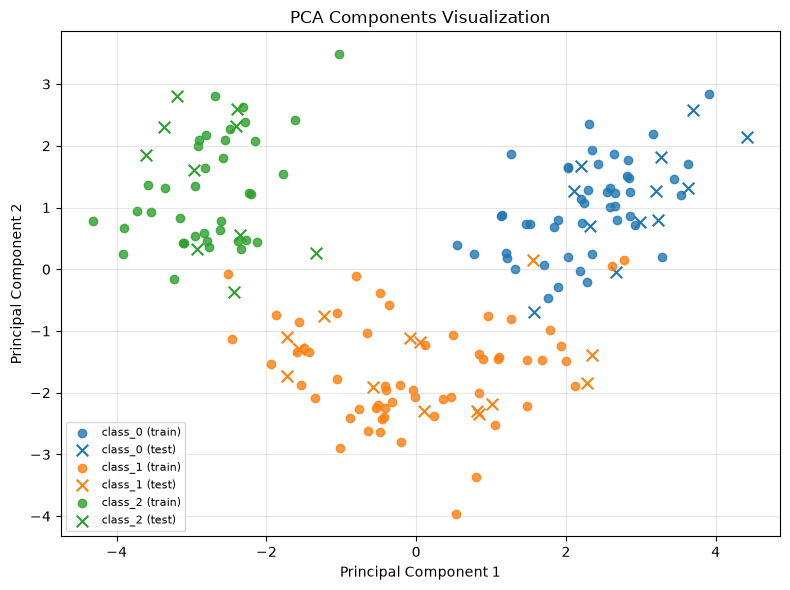

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["tab:blue", "tab:orange", "tab:green"]
for cls, name in enumerate(wine.target_names):
    mask = (y_train.values == cls)
    ax.scatter(X_train_pca2[mask, 0], X_train_pca2[mask, 1],
               color=colors[cls], label=f"{name} (train)", alpha=0.8)
    mask = (y_test.values == cls)
    ax.scatter(X_test_pca2[mask, 0], X_test_pca2[mask, 1],
               color=colors[cls], marker="x", s=70, label=f"{name} (test)")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title("PCA Components Visualization")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Завдання 3. Вплив кількості компонент на якість класифікації


In [6]:
component_counts = [2, 5, 10]
accuracies = []

print("Кількість компонент | Accuracy | Пояснена дисперсія")
for n in component_counts:
    pca = PCA(n_components=n, random_state=42)
    Xtr = pca.fit_transform(X_train_scaled)
    Xte = pca.transform(X_test_scaled)

    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(Xtr, y_train)
    acc = accuracy_score(y_test, clf.predict(Xte))
    accuracies.append(acc)
    print(f"{n:>19} | {acc:.4f}   | {pca.explained_variance_ratio_.sum():.3f}")

# Для порівняння: модель на всіх 13 ознаках без PCA
base = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_scaled, y_train)
print(f"\nДля порівняння, без PCA (13 ознак): {accuracy_score(y_test, base.predict(X_test_scaled)):.4f}")

Кількість компонент | Accuracy | Пояснена дисперсія
                  2 | 0.9167   | 0.551
                  5 | 0.9722   | 0.801
                 10 | 0.9722   | 0.962

Для порівняння, без PCA (13 ознак): 0.9722


## Завдання 4. Графік залежності точності від числа компонент


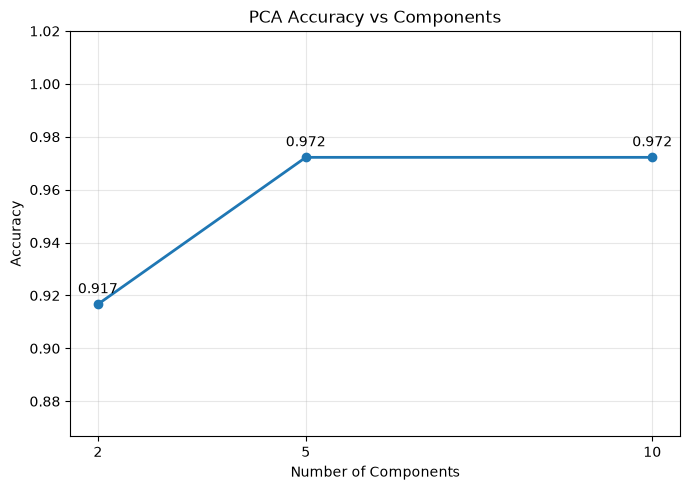

In [7]:
plt.figure(figsize=(7, 5))
plt.plot(component_counts, accuracies, marker="o", linewidth=2)
for x, a in zip(component_counts, accuracies):
    plt.annotate(f"{a:.3f}", (x, a), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xticks(component_counts)
plt.xlabel("Number of Components")
plt.ylabel("Accuracy")
plt.title("PCA Accuracy vs Components")
plt.ylim(min(accuracies) - 0.05, 1.02)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pca_accuracy_results.png", dpi=150)
plt.show()